Libraries loaded.
Dataset shape: (2087, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Pearson r: 0.4575, p-value: 0.000000
p-value < 0.05: Reject H0. There is evidence of a statistically significant linear correlation.
Training observations: 1669
Testing observations: 418
Training proportion: 80%
Testing proportion:  20%
Equation: Weight = -129.4596 + 127.1391 * Height
                            OLS Regression Results                            
Dep. Variable:                 Weight   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     426.4
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.55e-84
Time:                        17:02:54   Log-Likelihood:                -7621.2
No. Observations:                1669   AIC:                         1.525e+04
Df Residuals:                    1667   BIC:                         1.526e+04
Df Model:                           1                                         
Cov

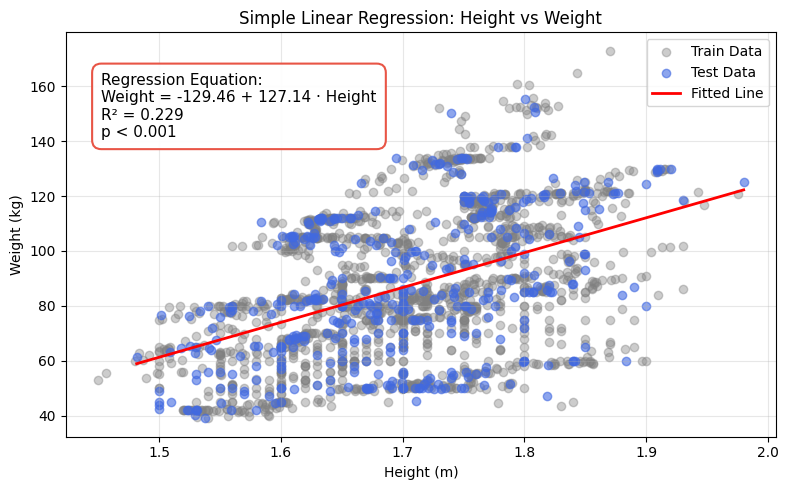

In [15]:
# ============================================================
# PART 1: IMPORTS AND CONFIGURATION
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

ALPHA = 0.05
RANDOM_STATE = 42
TEST_SIZE = 0.20
print("Libraries loaded.")

# ============================================================
# PART 2: DATA LOADING AND CLEANING
# ============================================================
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
df = df.drop_duplicates()
print(f"Dataset shape: {df.shape}")
display(df.head())

# ============================================================
# PART 3: SIMPLE LINEAR REGRESSION (HEIGHT -> WEIGHT)
# ============================================================
simple_data = df[["Height", "Weight"]].dropna().copy()

# Step 3.1: Correlation Analysis
r, corr_p = stats.pearsonr(simple_data["Height"], simple_data["Weight"])
print(f"Pearson r: {r:.4f}, p-value: {corr_p:.6f}")

if corr_p < ALPHA:
    print(
        f"p-value < {ALPHA}: Reject H0. "
        "There is evidence of a statistically significant linear correlation.")
else:
    print(
        f"p-value >= {ALPHA}: Do not reject H0. "
        "There is insufficient evidence of a statistically significant linear correlation.")

# Step 3.2: Train/Test Split
X_lin = simple_data[["Height"]]
y_lin = simple_data["Weight"]
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_lin, y_lin, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training observations:", len(X_train_l))
print("Testing observations:", len(X_test_l))

print(f"Training proportion: {len(X_train_l) / len(simple_data):.0%}")
print(f"Testing proportion:  {len(X_test_l) / len(simple_data):.0%}")

# Step 3.3: Model Fitting & Equation
lin_model = LinearRegression()
lin_model.fit(X_train_l, y_train_l)
y_pred_l = lin_model.predict(X_test_l)

intercept = lin_model.intercept_
slope = lin_model.coef_[0]
print(f"Equation: Weight = {intercept:.4f} + {slope:.4f} * Height")

# Step 3.4: OLS Significance Testing (t-test & F-test)
X_train_sm = sm.add_constant(X_train_l)
ols_results = sm.OLS(y_train_l, X_train_sm).fit()
print(ols_results.summary())

# Step 3.5: Performance Metrics (MAE, MSE, RMSE, MAPE, R2)
mae = mean_absolute_error(y_test_l, y_pred_l)
mse = mean_squared_error(y_test_l, y_pred_l)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test_l - y_pred_l) / y_test_l)) * 100
r2 = r2_score(y_test_l, y_pred_l)

metrics_linear = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'MAPE (%)', 'R-squared'],
    'Value': [round(mae, 4), round(mse, 4), round(rmse, 4), round(mape, 2), round(r2, 4)]
})
print("Linear Regression Metrics:")
print(metrics_linear)

# Step 3.6: Visualization (Scatter Plot with Fitted Line)
sorted_indices = X_test_l["Height"].argsort()
plt.figure(figsize=(8, 5))
plt.scatter(X_train_l, y_train_l, color='gray', alpha=0.4, label='Train Data')
plt.scatter(X_test_l, y_test_l, color='royalblue', alpha=0.6, label='Test Data')
plt.plot(X_test_l.iloc[sorted_indices], y_pred_l[sorted_indices], color='red', linewidth=2, label='Fitted Line')
box_text = (
    "Regression Equation:\n"
    f"Weight = {intercept:.2f} + {slope:.2f} · Height\n"
    f"R² = {r2:.3f}\n"
    f"p < 0.001"
)
plt.gca().text(0.05, 0.90, box_text, transform=plt.gca().transAxes, fontsize=11,
               verticalalignment='top',
               bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffffff', edgecolor='#e74c3c', linewidth=1.5, alpha=0.95))
plt.title('Simple Linear Regression: Height vs Weight')
plt.xlabel('Height (m)')
plt.ylabel('Weight (kg)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('simple_linear_regression.png', dpi=300)
plt.show()



,NObeyesdad,Obesity_Binary
0,Normal_Weight,0
1,Normal_Weight,0
2,Normal_Weight,0
3,Overweight_Level_I,0
4,Overweight_Level_II,0


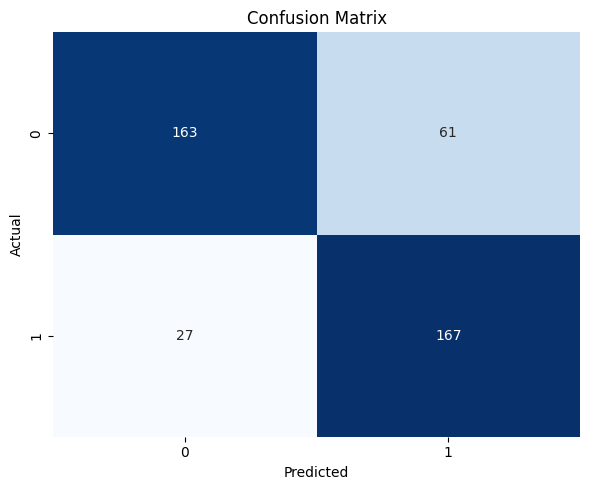

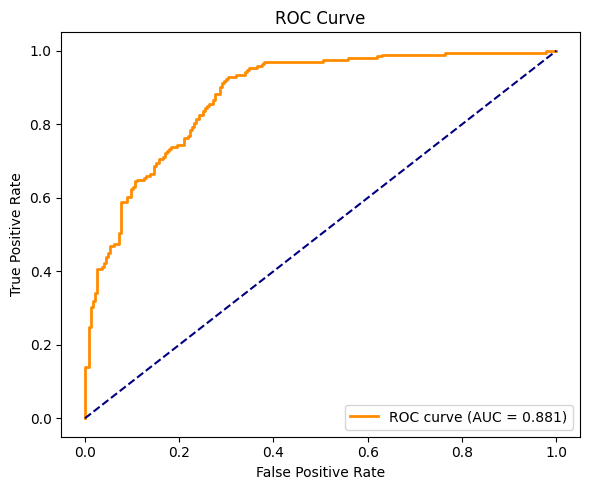

Logistic Regression Metrics:
      Metric   Value
0   Accuracy  0.7895
1  Precision  0.7325
2     Recall  0.8608
3   F1-score  0.7915
4    ROC-AUC  0.8808
Sample Predictions & Probabilities:
   Actual  Predicted_Class  Obesity_Probability
0       1                0               0.4623
1       1                1               0.9029
2       0                0               0.3253
3       0                0               0.2834
4       1                1               0.7887
5       0                0               0.1780
6       0                1               0.7269
7       1                1               0.8534
8       0                0               0.0276
9       0                0               0.0112


In [17]:
# ============================================================
# PART 4: BINARY LOGISTIC REGRESSION (PREVENTING DATA LEAKAGE)
# ============================================================
# Step 4.1: Target Formulation & Feature Preparation
df['Obesity_Binary'] = df['NObeyesdad'].apply(lambda x: 1 if 'Obesity' in x else 0)
display(df[['NObeyesdad', 'Obesity_Binary']].head())


# Usuwamy cel tekstowy, cel binarny oraz cechy wyciekowe (Weight, Height)
X_log = df.drop(columns=['NObeyesdad', 'Obesity_Binary', 'Weight', 'Height'])
X_log_encoded = pd.get_dummies(X_log, dtype=int)
y_log = df['Obesity_Binary']

# Step 4.2: Train/Test Split & Scaling
X_tr_log, X_te_log, y_tr_log, y_te_log = train_test_split(
    X_log_encoded, y_log, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
scaler_log = StandardScaler()
X_tr_log_scaled = scaler_log.fit_transform(X_tr_log)
X_te_log_scaled = scaler_log.transform(X_te_log)

# Step 4.3: Model Fitting & Coefficients
log_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_model.fit(X_tr_log_scaled, y_tr_log)

y_pred_log = log_model.predict(X_te_log_scaled)
y_prob_log = log_model.predict_proba(X_te_log_scaled)[:, 1]

# Step 4.4: Confusion Matrix & Classification Metrics
cm = confusion_matrix(y_te_log, y_pred_log)
fpr, tpr, _ = roc_curve(y_te_log, y_prob_log)
auc_val = roc_auc_score(y_te_log, y_prob_log)

# Confusion Matrix
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_cm)
ax_cm.set_title('Confusion Matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('logistic_confusion_matrix.png', dpi=300)
plt.show()

# ROC Curve
fig_roc, ax_roc = plt.subplots(figsize=(6, 5))
ax_roc.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.3f})')
ax_roc.plot([0, 1], [0, 1], color='navy', linestyle='--')
ax_roc.set_title('ROC Curve')
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate')
ax_roc.legend()
plt.tight_layout()
plt.savefig('logistic_roc_curve.png', dpi=300)
plt.show()

metrics_log = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Value': [
        round(accuracy_score(y_te_log, y_pred_log), 4),
        round(precision_score(y_te_log, y_pred_log), 4),
        round(recall_score(y_te_log, y_pred_log), 4),
        round(f1_score(y_te_log, y_pred_log), 4),
        round(auc_val, 4)
    ]
})
print("Logistic Regression Metrics:")
print(metrics_log)



# Step 4.5: Probability Predictions on Test Set
pred_probs_df = pd.DataFrame({
    'Actual': y_te_log.values[:10],
    'Predicted_Class': y_pred_log[:10],
    'Obesity_Probability': np.round(y_prob_log[:10], 4)
})
print("Sample Predictions & Probabilities:")
print(pred_probs_df)

